# MC2fit Tutorial: 2. Masking

This notebook prepares Legacy Survey cutouts for **MC2fit**, a multi-component GALFIT-based pipeline from the [`galaxydiver/MC2fit`](https://github.com/galaxydiver/MC2fit) repository.

The goal of this notebook is still **not yet to perform the final science fit**. Instead, it prepares the masking for the fitting.


In [1]:
# ============================================================
# Imports
# ============================================================
# Standard numerical and table-handling packages
import numpy as np
import pandas as pd

# Plotting and visualization
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import AutoMinorLocator

# General utilities
import pickle
import time
import copy
import random
import os
import glob
import shutil
from pathlib import Path
from dataclasses import dataclass
from multiprocessing import Pool
import subprocess
import warnings

# Astropy tools for statistics, FITS I/O, WCS, cutouts, and visualization
from astropy.stats import sigma_clip, sigma_clipped_stats
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.utils.data import download_file
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval, ImageNormalize, AsinhStretch
from astropy.modeling.functional_models import Sersic1D, Sersic2D

# Image processing
import skimage
from skimage.transform import resize

# ============================================================
# Custom MC2fit modules
# Repository: https://github.com/galaxydiver/MC2fit
# ============================================================
# Array/path utilities
import DH_array as dharray
import DH_path as dhpath

# Download Legacy Survey images, PSF files, and related products
import DH_LegacyCrawling as dhcrawl

# File and directory management utilities
import DH_FileCheck as dhfc

# Main MC2fit configuration and execution tools
import DH_MC2fit as dhmc2fit


This machine : SO desktop computer
LegacyCrawling - Loading summary fits south :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-south.fits
LegacyCrawling - Loading summary fits south (DR10) :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr10-south.fits
LegacyCrawling - Loading summary fits north :  /home/donghyeon/ua/udg/galfit/galfit/RawData/survey-bricks-dr9-north.fits


## Working directory, Settings

You can copy these cells from the previous notebook example

In [19]:
## Create a dedicated working directory for this example and move into it.
dir_main = './Galfit_Run/PSB_new'
os.chdir(dir_main)

FileNotFoundError: [Errno 2] No such file or directory: './Galfit_Run/PSB_new'

In [20]:
# Number of CPU workers to use for multicore tasks.
# Use a moderate value for network downloads. Too many simultaneous requests
# can trigger server-side rate limits or timeout errors.
Ncore = 4

# Legacy Survey pixel scale in arcsec / pixel.
# This is needed when converting pixel-based sizes to angular units.
plate_scale = 0.262

# Cutout size in pixels.
# For image_size=121, each cutout is roughly 121 * 0.262 arcsec across.
image_size = 121

## Estimated sky value 
est_sky=10 

# Load the target catalog.
# The catalog must contain at least RA and dec columns.
fn = "./fulldata.csv"
target_catalog = pd.read_csv(fn)

# Extract sky coordinates used by the Legacy Survey download functions.
# The coordinate array has shape (N_target, 2), with columns [RA, dec].
col = ['ra', 'dec']
coord_array = target_catalog[col].to_numpy().astype(float)

# Quick sanity check: display the RA/Dec array that will be passed to download functions.
len(coord_array)


238

## Copy the working directory

In this step, we copy the downloaded survey products to a new working directory for fitting.

The directory `gal_dat/` stores the raw downloaded files. These files should be kept as the original downloaded products so that you do not need to download them again when you want to restart the fitting process.

The directory `gal_out/` is used for the fitting-ready products and fitting outputs. This includes files that may be modified, overwritten, or newly generated during the fitting process.

Keeping the raw data and fitting products separate makes debugging safer. For example, after finishing one fitting run, you may want to remove the fitting results and re-fit the data with different parameters. In that case, you can simply reset `DI` and rebuild the fitting directory without downloading the survey products again.

In short:

- `DIdat` points to the raw downloaded data directory, `gal_dat/`.
- `DI` points to the fitting/output directory, `gal_out/`.
- If you need to restart the fitting, reset `DI`, not `DIdat`.
- You usually do not need to download the files again unless the raw files in `gal_dat/` are missing or corrupted.

In [4]:
# DIdat manages the raw downloaded survey products.
# Each target gets a folder named according to folder_rule, e.g., gal0000/, gal0001/, ...
DIdat = dhfc.DirInfo(
    './',
    dir_work_base='gal_dat/',           # downloaded files
    folder_rule='gal%04d/',             # four-digit folder names; supports up to 9999 targets
                                      # to use five-digit names, use 'gal%05d/'
    coord_array=coord_array,
    idlist=np.arange(len(coord_array)), # internal target IDs
    catalogname_list=target_catalog['name'], # human-readable target names
)

# Print the number of raw-data target directories.
print(len(DIdat.dir_work_list))

# DI manages the standardized fitting/output directory tree.
# The raw data in gal_dat/ are copied or linked into gal_out/ for fitting.
# You can change the folder name when you want to make another set of the fittings.
DI = DIdat.change_work_base('gal_out/', return_new=True)

# Print the number of fitting/output target directories.
print(len(DI.dir_work_list))

238
238


In [5]:
## Check the data
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr9_', regionlist=['n'], silent=True)
dhfc.generate_checkpixel(DIdat, Ncore=15, fna_image='image_dr10_', regionlist=['s'], silent=True)
CheckPixels=dhfc.CheckPixel(DIdat, bad_pixel_crit=1e9)
np.where(CheckPixels.pixel_median<1)

Check pixels: ng:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: nr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sg:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s


Check pixels: sr:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.1 s
Region - s Band - g  exist : 161
Region - s Band - r  exist : 154
Region - s Total exist : 154
Region - n Band - g  exist : 79
Region - n Band - r  exist : 79
Region - n Total exist : 76
List South : 154
List North : 61
List Bad : 23


(array([], dtype=int64), array([], dtype=int64), array([], dtype=int64))

## Why symbolic links are useful

Raw downloaded files may have survey-specific names, for example `image_dr9_n` or `image_dr10_s`. MC2fit is easier to run if every target directory contains standardized names such as:

- `image_lg.fits`
- `image_lr.fits`
- `sigma_lg.fits`
- `sigma_lr.fits`
- `psf_model_lg.fits`
- `psf_model_lr.fits`

The links point to the chosen raw files without duplicating large FITS data.

### Generate links into the GALFIT directory

The next cell creates links from `gal_dat/` to `gal_out/`. After this step, later code should mostly use `DI` / `gal_out/` rather than the raw download directory.

In [6]:
# Create symbolic links from the chosen raw survey files into the fitting directory.
#
# The raw files can have survey-specific names, but later MC2fit steps expect
# standardized names. This function creates those standardized links.
DI.make_dir_work()

dhfc.multicore_generate_link_img(
    DIdat,
    DI,
    CheckPixels,
    Ncore=4,
    is_psf_others=True
)


Generate image links:   0%|          | 0/238 [00:00<?, ?it/s]

Done! | Time: 0.0 s
Linked: 215 / 238
Skipped: 23 / 238


array([ True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True,  True,
        True, False,  True, False,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True,

# PSF measurement

This section estimates the PSF FWHM for each usable target.

## Purpose

The PSF size is useful for:

- sanity-checking downloaded PSFs,
- choosing mask dilation sizes,
- interpreting whether compact sources are resolved,
- setting fitting constraints or visual diagnostics.

## Method used here

The notebook uses a simple empirical estimate:

1. find the brightest PSF pixel,
2. extract horizontal and vertical 1D slices through the peak,
3. fit each slice with a Gaussian,
4. convert Gaussian sigma to FWHM.

This is not a full PSF model analysis, but it is sufficient as a quick quality check.

## Keep only targets that passed the file-quality check

`DIgood` contains only targets not flagged as bad by `CheckPixels`. This avoids running PSF and masking code on missing or invalid FITS files.

In [7]:
## Keep only the good targets for downstream processing.
DIgood = dhfc.cut_DirInfo(DI, np.invert(CheckPixels.list_bad))
len(DI.dir_work_list), len(DIgood.dir_work_list)


Previous : 238  |  New :  215


(238, 215)

In [8]:
psf_lg = dhmc2fit.multicore_measure_psf(DIgood, fni_psf='psf_model_lg.fits', fn_save = 'psf_size_lg.dat')
psf_lr = dhmc2fit.multicore_measure_psf(DIgood, fni_psf='psf_model_lr.fits', fn_save = 'psf_size_lr.dat')

Start multicore PSF measurement
● Backend: thread
● Number of workers: 16
● Number of targets: 215
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: False


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.3 s
Start multicore PSF measurement
● Backend: thread
● Number of workers: 16
● Number of targets: 215
======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 16
● Backend: thread
● Using try/except: False


partial [thread]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.3 s


# Masking

Masking is the most important data-preparation step in this notebook.

## Purpose

GALFIT/MC2fit should fit the target galaxy, not contaminating sources. A mask tells the fitting code which pixels to ignore.

Typical things to mask:

- foreground stars,
- nearby galaxies,
- bright compact contaminants,
- image artifacts,
- detector defects.
- center core of the galaxy (if necessary)


## Remove old masks

Before testing new masking parameters, delete previous mask outputs if exists. Otherwise, old files can be confused with newly generated masks.

In [10]:
## Remove previously generated mask files so the masking test starts cleanly.
res = dhfc.multicore_remove(DIgood.dir_work_list, fna='masking*.fits', Ncore=15)


Remove files:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.0 s


## Manual masking test on one target

Before running the full sample, test the masking settings on one representative target.

This is strongly recommended because mask parameters are empirical. A threshold that works for one image depth or galaxy morphology may fail for another.

### Choosing mask parameters

The main parameters are:

| Parameter | Meaning |
|---|---|
| `thresh` | detection threshold for pixels/objects |
| `is_relative` | if `True`, threshold is relative to background RMS |
| `minarea` | minimum number of connected pixels required |
| `suppress_center_size` | central radius protected from masking |
| `dilate_iterations` | expands masks to cover source wings |

A good mask should remove contaminants while preserving the target galaxy.

### Multi-stage masking strategy

The masking workflow uses several passes because different contaminants require different thresholds.

1. **Bright compact mask**: catches obvious stars or bright artifacts.
2. **Main mask**: masks normal contaminating objects above the background.
3. **Nearby-object mask**: more aggressive masking farther from the galaxy center.
4. **Compact central-source pass**: optionally identifies very bright nuclear/cluster-like sources.

This staged approach is safer than using one global threshold for everything.

## Main lightweight masking class

`Masking_LITE` is a notebook-level helper class. It wraps several common masking operations:

- load image and previous mask,
- estimate background,
- detect objects,
- protect the central region,
- optionally dilate masks,
- return several mask products.

The class is intentionally flexible, but that also means parameter choices matter. Always inspect the mask visually before trusting it.

'https://www.legacysurvey.org/viewer/jpeg-cutout?ra=176.6515352&dec=30.0854544&size=121&layer=ls-dr10'

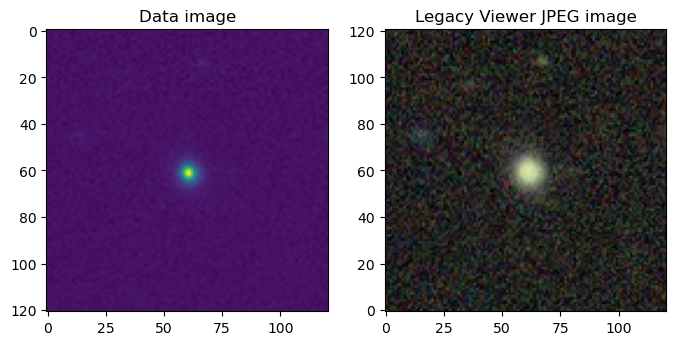

In [23]:
## Inspect one target manually before running the full sample.
i = 3
fn_image = DIgood.dir_work_list[i] + 'image_lr.fits'
dat = fits.getdata(fn_image)

fig=plt.figure(figsize=(8,6))
gs=gridspec.GridSpec(1,2)
ax0=plt.subplot(gs[0])
plt.title("Data image")
plt.imshow(dat[::-1])
ax0=plt.subplot(gs[1])
plt.title("Legacy Viewer JPEG image")
dhmc2fit.Legacy_get_JPEG(DIgood.coord_array[i][0], DIgood.coord_array[i][1], size=image_size)


'https://www.legacysurvey.org/viewer/jpeg-cutout?ra=202.3219798&dec=19.6709745&size=121&layer=ls-dr10'

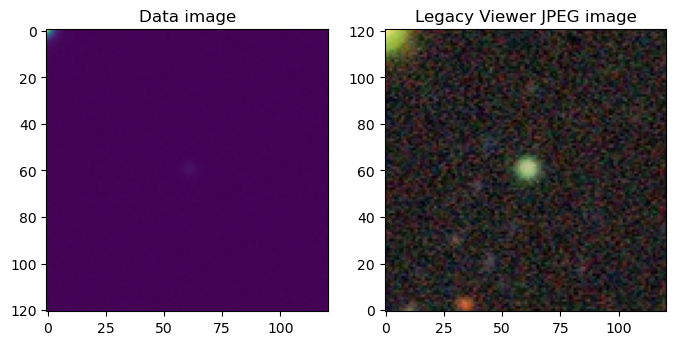

In [12]:
## Inspect one target manually before running the full sample.
i = 4
fn_image = DIgood.dir_work_list[i] + 'image_lr.fits'
dat = fits.getdata(fn_image)

fig=plt.figure(figsize=(8,6))
gs=gridspec.GridSpec(1,2)
ax0=plt.subplot(gs[0])
plt.title("Data image")
plt.imshow(dat[::-1])
ax0=plt.subplot(gs[1])
plt.title("Legacy Viewer JPEG image")
dhmc2fit.Legacy_get_JPEG(DIgood.coord_array[i][0], DIgood.coord_array[i][1], size=image_size)


In [12]:
masking_params = {
    ## Mask bright objects
    "Mask1": dict(
        thresh=1, minarea=1,  ## Threshold & Minimum pixel numbers
        is_relative=False,
        suppress_center_size=5, ## If you don't want mask the center. Size [pixel]
        silent=True,
        dilate_iterations=1,
    ),

    ## Main masking
    "Mask2": dict(
        thresh=2,
        minarea=5,
        suppress_center_size=30,
        suppress_keep_prev_mask=True,
        silent=True,
        dilate_iterations=1,
    ),

    ## Nearby galaxies masking
    "Mask3": dict(
        thresh=1,
        minarea=1,
        suppress_center_size=50,
        suppress_keep_prev_mask=True,
        silent=True,
        dilate_iterations=1,
    ),

    ## Possible NSC masking
    "Mask4": dict(
        thresh=10,
        minarea=5,
        suppress_center_size=-1,
        return_new_mask_only=True,
        silent=True,
        dilate_iterations=1,
        bkg_bw=8,
        bkg_bh=8,
    ),
}

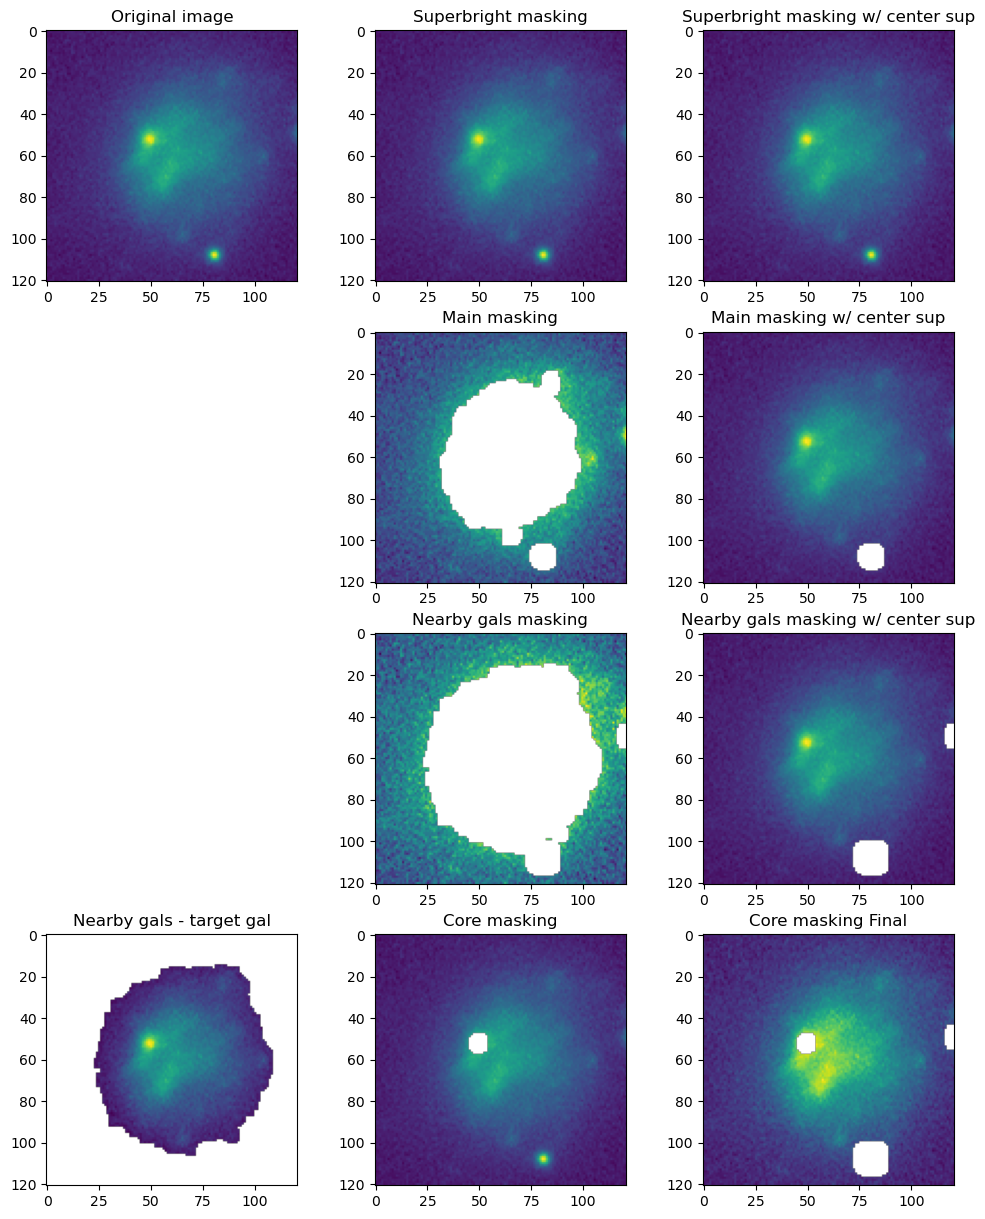

In [13]:
ctx = dhmc2fit.run_masking_preset(
    fn_image,
    masking_params,
)

Mask1 = ctx["Mask1"]
Mask2 = ctx["Mask2"]
Mask3 = ctx["Mask3"]
Mask4 = ctx["Mask4"]


fig=plt.figure(figsize=(12,15))
gs=gridspec.GridSpec(4,3)
ax0=plt.subplot(gs[0])
plt.title("Original image")
plt.imshow(Mask1.imagedata[::-1])
ax0=plt.subplot(gs[1])
plt.title("Superbright masking")
newdat=np.ma.masked_array(Mask1.imagedata, Mask1.mask_main)
plt.imshow(newdat[::-1])
ax0=plt.subplot(gs[2])
plt.title("Superbright masking w/ center sup")
newdat=np.ma.masked_array(Mask1.imagedata, Mask1.mask_main_sup)
plt.imshow(newdat[::-1])


ax0=plt.subplot(gs[4])
plt.title("Main masking")
newdat=np.ma.masked_array(Mask2.imagedata, Mask2.mask_main)
plt.imshow(newdat[::-1])
ax0=plt.subplot(gs[5])
plt.title("Main masking w/ center sup")
newdat=np.ma.masked_array(Mask2.imagedata, Mask2.mask_main_sup)
plt.imshow(newdat[::-1])
# ax0=plt.subplot(gs[6])
# plt.title("Main masking target gal")
# newdat=np.ma.masked_array(Mask2.imagedata, Mask2.mask_center)
# plt.imshow(newdat[::-1])

ax0=plt.subplot(gs[7])
plt.title("Nearby gals masking")
newdat=np.ma.masked_array(Mask3.imagedata, Mask3.mask_main)
plt.imshow(newdat[::-1])
ax0=plt.subplot(gs[8])
plt.title("Nearby gals masking w/ center sup")
newdat=np.ma.masked_array(Mask3.imagedata, Mask3.mask_main_sup)
plt.imshow(newdat[::-1])
ax0=plt.subplot(gs[9])
plt.title("Nearby gals - target gal")
newdat=np.ma.masked_array(Mask3.imagedata, Mask3.mask_center_inv)
plt.imshow(newdat[::-1])

ax0=plt.subplot(gs[10])
plt.title("Core masking")
newdat=np.ma.masked_array(Mask4.imagedata, Mask4.mask_main)
plt.imshow(newdat[::-1])
ax0=plt.subplot(gs[11])
plt.title("Core masking Final")

newdat=np.ma.masked_array(Mask4.imagedata, Mask4.mask_main_nsc)
plt.imshow(newdat[::-1])

In [14]:
save_config = [
    ("masking_{band}{suffix}.fits",     "Mask2.mask_main_sup", "fits"),
    ("masking_{band}{suffix}_nb.fits",  "Mask3.mask_main_sup", "fits"),
    ("masking_{band}{suffix}_d.fits",   "Mask4.mask_main_nsc", "fits"),
    ("maskobj_{band}{suffix}_d.npy",    "Mask4.obj_main_nsc",  "npy"),
    ("masking_{band}{suffix}_o.fits",   "galmask1",            "fits"),
    ("masking_{band}{suffix}_od.fits",  "galmask2",            "fits"),
]

## Run masking for all targets

After choosing acceptable parameters from the single-target test, this section applies the same logic to every target.

The function creates multiple mask products:

| File pattern | Meaning |
|---|---|
| `masking_<band>.fits` | main mask |
| `masking_<band>_nb.fits` | nearby-object / broader mask |
| `masking_<band>_d.fits` | compact-object or NSC-oriented mask |
| `masking_<band>_o.fits` | cleaned object segmentation mask |
| `masking_<band>_od.fits` | cleaned compact-object segmentation mask |

The exact scientific interpretation depends on how the masks are used in the later fitting notebook.

### Batch masking function

The next function applies the staged masking recipe to every target in a selected band.

For debugging, set `Ncore=1` and `debug=True`. Once the first target works, run the full sample with multiple cores.

In [15]:
# Run the masking pipeline on all good targets in g band.
# Start with a small Ncore if debugging; increase once the first few targets work.
dhmc2fit.multicore_masking_fixed(
    DIgood,
    masking_params,
    save_config,
    Ncore=4,
    band="g",
    suffix="",
    overwrite=True,
)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 4
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=object)

In [16]:
# Run the masking pipeline on all good targets in r band.
dhmc2fit.multicore_masking_fixed(
    DIgood,
    masking_params,
    save_config,
    Ncore=4,
    band="r",
    suffix="",
    overwrite=True,
)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 4
● Backend: process
● Using try/except: True


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 2.3 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=object)

**Checkpoint:** before combining g and r masks, visually inspect several targets in both bands. Mask failures are much easier to catch here than after fitting.

## Combine g- and r-band masks

A contaminating object may be obvious in one band but faint in another. Combining masks from both bands gives a more conservative mask for structural fitting.

The combined mask is stored with a new band label such as `c`, meaning “combined”.

### Mask-combination function

This function combines masks from two bands. The usual logic is conservative: if a pixel is masked in either band, it should be masked in the combined product.

In [17]:
task=dhmc2fit.multicore_masking_combine(DIgood, suffix='', 
                               masknamelist=['.fits', '_nb.fits', '_d.fits','_o.fits','_od.fits'],
                               Ncore=Ncore)

======== Parallel Briefing ========
● Function: partial
● Number of loops: 215
● Number of workers: 4
● Backend: process
● Using try/except: False


partial [process]:   0%|          | 0/215 [00:00<?, ?it/s]

Done! | Time: 0.5 s
======== Parallel summary ========
● Succeed: 215 / 215
● Failed: 0 / 215
● Warning: 0 / 215



# Sigma extraction (Skip)

In [ ]:
# Multiprocessing helper used by the MC2fit pipeline
import DH_multicore as mulcore

## g-band

In [ ]:
## Remove old sigma_g files before regenerating them.
dhfc.multicore_remove(DI.dir_work_list, Ncore=4, fna='sigma_g.fits', show_progress=1000,)


In [ ]:
## Build an MC2fit Setting object whose purpose here is only to extract sigma images.
## In DH_MC2fit.py, Setting stores file paths, image scale, runtime options, and output choices.
MC2fitSet_sigma_g = dhmc2fit.Setting(
    plate_scale=plate_scale,
    image_size=image_size,
    zeromag=0,
    est_sky=0,
    fni_sigma=None,              ## no external sigma file is supplied
    is_run_galfit_dir_work=True, ## run inside each target directory
    extract_sigma=True,          ## ask GALFIT / MC2fit to generate sigma
    output_block=False,          ## do not run the final science fit at this stage
)
MC2fitSet_sigma_g


In [ ]:
## Create a minimal Runlist.
## In DH_MC2fit.py, Runlist defines model components, initial guesses, and constraints.
est_params_array = np.array([[np.nan, np.nan, 20, 30, 1, np.nan, np.nan]], dtype='object')

RunlistSig = dhmc2fit.Runlist(
    MC2fitSet_sigma_g,
    namelist='test20',
    complist=['sersic2'],
    est_params_array=est_params_array,
    group_id=0,
    size_conv=101,
    lim_pos=np.array([[200, 300]]),
    lim_n=[[0, 2]],
    lim_reff=np.nan,
    lim_ar=[[0.2, 1.1]],
)
RunlistSig


## r-band

In [ ]:
## Repeat the same sigma-extraction idea for the r band.
MC2fitSet_sigma_r = dhmc2fit.Setting(
    plate_scale=0.2,
    zeromag=0,
    fni_image='image_r.fits',
    band='r',
    fni_sigma=None,
    is_run_galfit_dir_work=True,
    extract_sigma=True,
    output_block=False,
)

## Run the sigma extraction.
Run = dhmc2fit.MC2fitRun_Mulcore(MC2fitSet_sigma_r, RunlistSig, DI)

## Rename the outputs to simpler standardized filenames if needed.
dhfc.multicore_rename(DI.dir_work_list, Ncore=4,
                      fna='galfit_r_base/sigma*',
                      prev_pattern='galfit_r_base/',
                      new_pattern='')


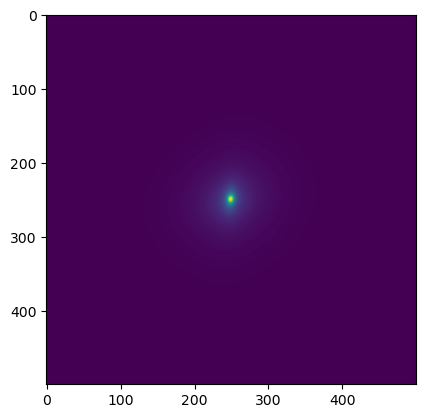

In [72]:
plt.imshow(fits.getdata('./gal_out/gal0000/galfit_g_fixed_n/output_rss_0.fits', ext=2))